In [ ]:
import pandas as pd
import numpy as np

# Пути к локальным файлам в текущей директории
red_file = "winequality-red.csv"
white_file = "winequality-white.csv"

# Загружаем оба датасета локально (разделитель — точка с запятой)
df_red = pd.read_csv(red_file, sep=';')
df_white = pd.read_csv(white_file, sep=';')

#Добавляем признак типа вина (1 — красное, 0 — белое)
df_red['is_red'] = 1
df_white['is_red'] = 0

# Мерджим (объединяем) в один общий датасет
df = pd.concat([df_red, df_white], ignore_index=True)

#Проверяем результат
print(f"Размер датасета красного вина: {df_red.shape}")
print(f"Размер датасета белого вина: {df_white.shape}")
print(f"Общий объединенный датасет: {df.shape}")
display(df.head())

Размер датасета красного вина: (1599, 13)
Размер датасета белого вина: (4898, 13)
Общий объединенный датасет: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

X = df.drop('quality', axis=1) # удаляем таргет и оставляет только признаки
y = df['quality'] # берем таргет

# делим на обучающую итоговую выборку
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67)

print(f"Размер обучающей выборки (X_train): {X_train.shape}")
print(f"Размер тестовой выборки (X_test): {X_test.shape}")


Размер обучающей выборки (X_train): (5197, 12)
Размер тестовой выборки (X_test): (1300, 12)


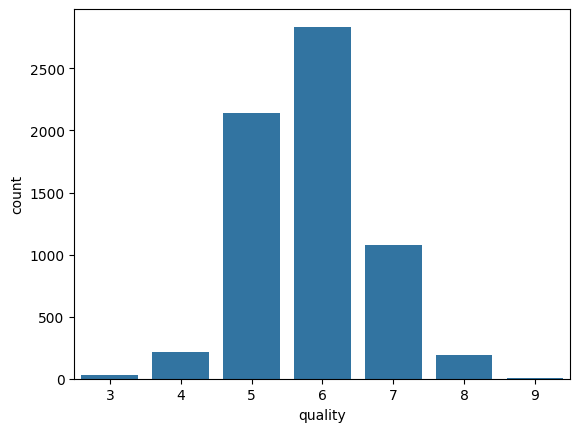

In [4]:
import seaborn as sb
import matplotlib.pyplot as plt
sb.countplot(x='quality',data=df)
plt.show()

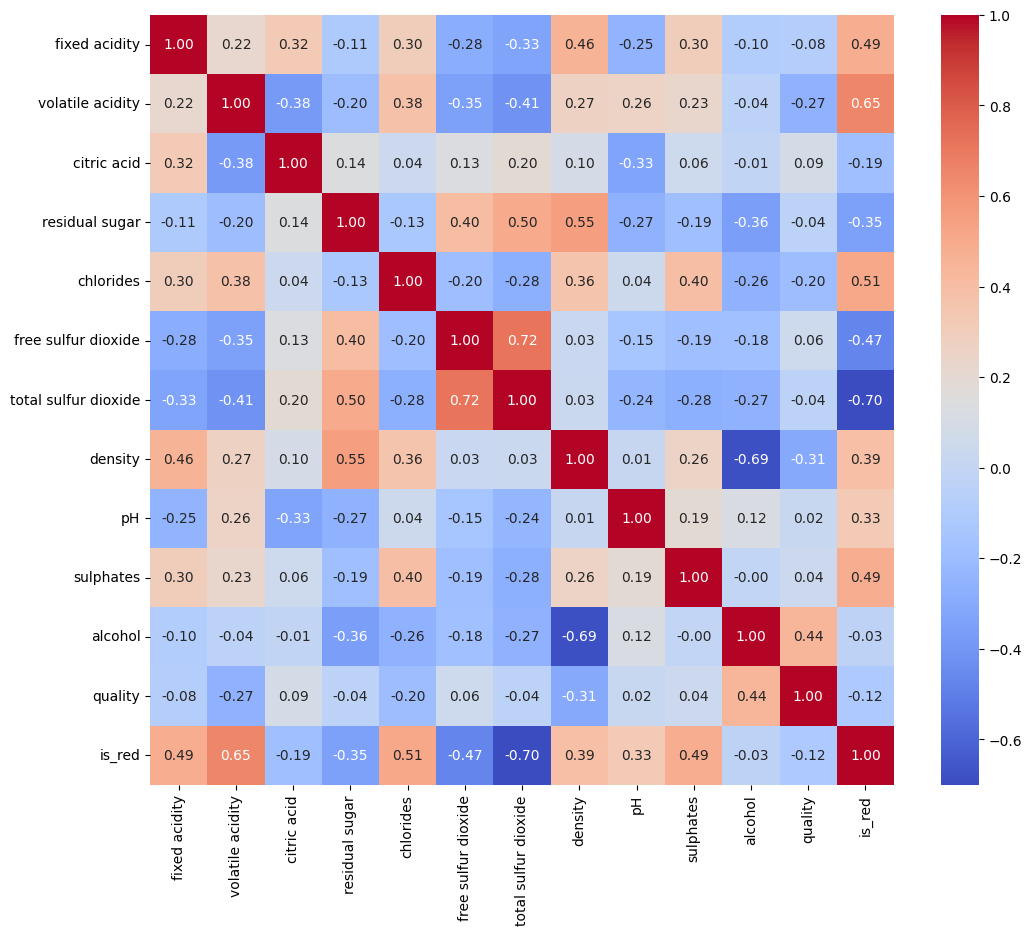

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
# выводим матрицу корреляций (насколько один параметр зависит от другого)
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), cmap="coolwarm", annot=True, fmt=".2f")
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

baseline_prediciton = y_train.median() # берем медиану по всей выборке
print(f"\nКонстанта для baseline (медиана train): {baseline_prediciton}")
y_pred_baseline = np.full_like(y_test, baseline_prediciton, dtype=float)

RMSE = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
MAE = mean_absolute_error(y_test, y_pred_baseline)

print(f"Baseline RMSE: {RMSE:.4f}")
print(f"Baseline MAE:  {MAE:.4f}")
# сделали по тупому предсказание медианы, любая наша модель должна обойти это значение


Константа для baseline (медиана train): 6.0
Baseline RMSE: 0.9013
Baseline MAE:  0.6508


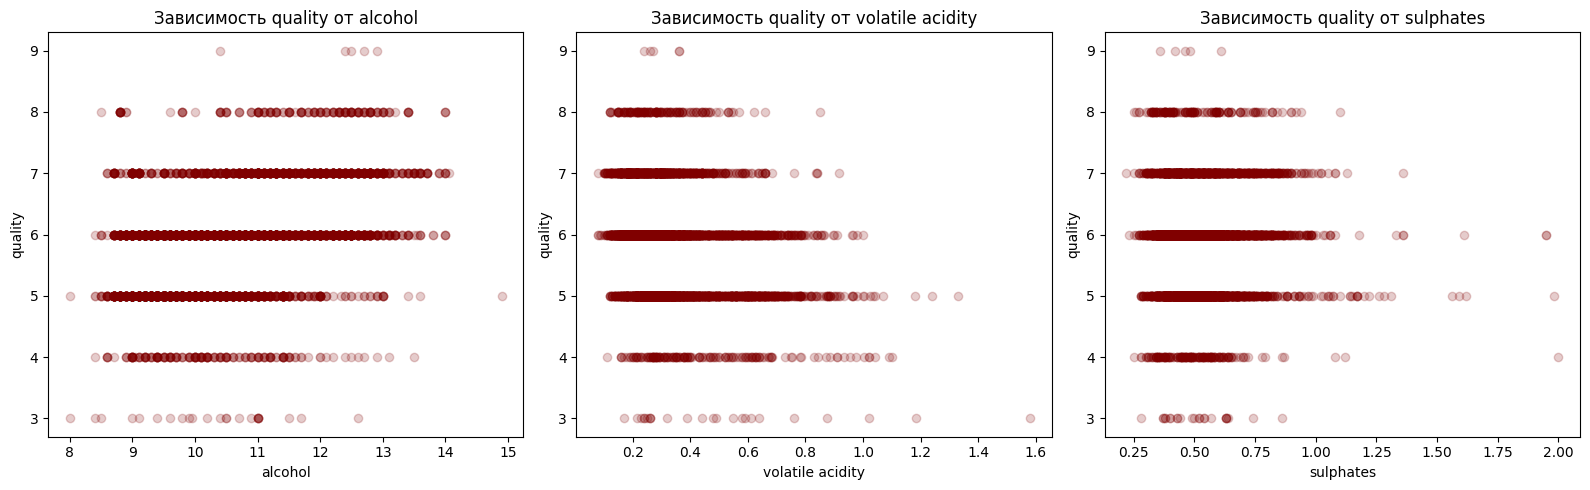

In [9]:
import matplotlib.pyplot as plt

# Визуализация зависимости качества вина от ключевых признаков
fig, axs = plt.subplots(figsize=(16, 5), ncols=3)
top_features = ["alcohol", "volatile acidity", "sulphates"]

for i, feature in enumerate(top_features):
    axs[i].scatter(X_train[feature], y_train, alpha=0.2, color='maroon')
    axs[i].set_xlabel(feature)
    axs[i].set_ylabel("quality")
    axs[i].set_title(f"Зависимость quality от {feature}")

plt.tight_layout()
plt.show()

In [10]:
# ЛИНЕЙНАЯ РЕГРЕССИЯ
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
XTrainAfterScaled = scaler.fit_transform(X_train)
XTestAfterScaled = scaler.transform(X_test)

# масштабирваоние признаков
lr_model = LinearRegression()
lr_model.fit(XTrainAfterScaled, y_train)
y_pred_lr = lr_model.predict(XTestAfterScaled)

y_pred_train = lr_model.predict(XTrainAfterScaled)

lr_model_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

lr_model_mae = mean_absolute_error(y_test, y_pred_lr)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))

print(f"Linear Regression RMSE: {lr_model_rmse:.4f}, MAE: {lr_model_mae:.4f}")
print(f"Linear Regression Train RMSE: {train_rmse:.4f}")
coefs = pd.Series(lr_model.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print("\nКоэффициенты Linear Regression (по модулю):")
print(coefs)

Linear Regression RMSE: 0.7165, MAE: 0.5620
Linear Regression Train RMSE: 0.7367

Коэффициенты Linear Regression (по модулю):
density                -0.276732
residual sugar          0.275480
alcohol                 0.275361
volatile acidity       -0.250235
is_red                  0.138985
fixed acidity           0.100239
sulphates               0.098677
free sulfur dioxide     0.074278
total sulfur dioxide   -0.073903
pH                      0.067244
citric acid            -0.024413
chlorides              -0.022328
dtype: float64


In [ ]:
# Считаем корреляцию признаков с таргетом на train
corrs = X_train.corrwith(y_train).abs()

# Оставляем только те признаки, где корреляция выше заданного порога 0.08
good_features = corrs[corrs > 0.08].index.tolist()
print(f"Признаки, которые мы оставляем для линейной регрессии: {good_features}")

# убераем из выборок признаки
X_train_filtered = X_train[good_features]
X_test_filtered = X_test[good_features]

# масштаб
scaler_f = StandardScaler()
X_tr_f_scaled = scaler_f.fit_transform(X_train_filtered)
X_te_f_scaled = scaler_f.transform(X_test_filtered)

# обучаем снова
lr_f = LinearRegression()
lr_f.fit(X_tr_f_scaled, y_train)
y_pred_lr_f = lr_f.predict(X_te_f_scaled)




print(f"Новый Linear Regression RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lr_f)):.4f}")
print(f"Новый Linear Regression MAE:  {mean_absolute_error(y_test, y_pred_lr_f):.4f}")

# ПРОМЕЖУТОЧНЫЕ ВЫВОДЫ
# Наибольший вклад по модулю вносят признаки alcohol, volatile acidity и sulphates.
# Их знаки совпадают с матрицей корреляций (алкоголь повышает оценку, летучая кислотность — понижает).

Признаки, которые мы оставляем для линейной регрессии: ['fixed acidity', 'volatile acidity', 'chlorides', 'density', 'alcohol', 'is_red']
Новый Linear Regression RMSE: 0.7356
Новый Linear Regression MAE:  0.5766


In [14]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Обучаем Ridge (L2) с подбором alpha
ridge = Ridge(alpha=10.0) # Сильный штраф
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

print(f"Ridge (L2) RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_ridge)):.4f}")

# 3. Обучаем Lasso (L1) с подбором alpha
lasso = Lasso(alpha=0.01) # Умеренный штраф
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)

print(f"Lasso (L1) RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lasso)):.4f}")

# 4. Сравниваем коэффициенты Lasso
lasso_coefs = pd.Series(lasso.coef_, index=X.columns)
print("\nКоэффициенты Lasso:")
print(lasso_coefs)

Ridge (L2) RMSE: 0.7168
Lasso (L1) RMSE: 0.7256

Коэффициенты Lasso:
fixed acidity          -0.000000
volatile acidity       -0.230047
citric acid            -0.012996
residual sugar          0.081869
chlorides              -0.017064
free sulfur dioxide     0.057442
total sulfur dioxide   -0.065588
density                -0.000000
pH                      0.004748
sulphates               0.071343
alcohol                 0.381480
is_red                  0.023804
dtype: float64


In [ ]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np

# 1. Создаем пайплайн: 
# Сначала полиномиальные признаки (degree=2), затем масштабирование, затем линейная регрессия
poly_lr_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# 2. Настраиваем кросс-валидацию (например, на 5 фолдов)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("Значения RMSE для каждого фолда (Полиномиальная регрессия 2-й степени):")
rmse_scores = []

# 3. Запускаем цикл кросс-валидации
for fold, (train_index, val_index) in enumerate(kf.split(X_train), start=1):
    # Разделяем данные на обучающую и валидационную выборку для текущего фолда
    if hasattr(X_train, "iloc"):
        X_tr, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_tr, y_val = y_train.iloc[train_index], y_train.iloc[val_index]
    else:
        X_tr, X_val = X_train[train_index], X_train[val_index]
        y_tr, y_val = y_train[train_index], y_train[val_index]
    
    # Обучаем пайплайн на текущем фолде
    poly_lr_pipeline.fit(X_tr, y_tr)
    
    # Делаем предсказание на валидационной части
    y_pred_val = poly_lr_pipeline.predict(X_val)
    
    # Считаем RMSE
    fold_rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    rmse_scores.append(fold_rmse)
    
    # Выводим результат для текущего фолда
    print(f"Фолд {fold}: RMSE = {fold_rmse:.4f}")

# 4. Итоговая статистика
print("-" * 45)
print(f"Среднее RMSE по кросс-валидации: {np.mean(rmse_scores):.4f}")
print(f"Стандартное отклонение: {np.std(rmse_scores):.4f}")

Значения RMSE для каждого фолда (Полиномиальная регрессия 2-й степени):
Фолд 1: RMSE = 0.7740
Фолд 2: RMSE = 0.7185
Фолд 3: RMSE = 0.6825
Фолд 4: RMSE = 0.7353
Фолд 5: RMSE = 0.7084
---------------------------------------------
Среднее RMSE по кросс-валидации: 0.7237
Стандартное отклонение: 0.0304


In [ ]:

# ПОДБОР ПААРМЕТРВО
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Задаем безопасную сетку параметров
param_distributions_safe = {
    'n_estimators': [100, 200],
    'max_depth': [8, 10, 12, 15],          # Ограничиваем глубину сверху
    'min_samples_split': [5, 10, 15],      # Заставляем копить больше объектов
    'min_samples_leaf': [2, 4, 6],         # Запрещаем листья с 1 объектом
    'max_features': ['sqrt', 0.8],
    'bootstrap': [True]                    # включаем бэггинг
}

# Инициализируем базовую модель
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# Настраиваем поиск, передавая нееперобученную безопасную сетку
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions_safe,
    n_iter=30,               # количество случайных комбинаций
    cv=5,                    # 5 блоков кросс-валидации
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,               # все ядра процессора
    verbose=1
)

# Запускаем поиск
random_search.fit(XTrainAfterScaled, y_train)

print("\nЛучшие безопасные параметры для Random Forest:")
print(random_search.best_params_)

# Достаем лучшую модель
best_rf_model = random_search.best_estimator_

# Проверяем RMSE на трейне (чтобы убедиться, что нет переобучения!)
y_pred_train = best_rf_model.predict(XTrainAfterScaled)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"RMSE на трейне (должен быть около 0.5-0.55): {train_rmse:.4f}")

# Проверяем на тесте
y_pred_best = best_rf_model.predict(XTestAfterScaled)
best_rmse = np.sqrt(mean_squared_error(y_test, y_pred_best))
best_mae = mean_absolute_error(y_test, y_pred_best)

print(f"Улучшенный безопасный Random Forest - Test RMSE: {best_rmse:.4f}, MAE: {best_mae:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Лучшие безопасные параметры для Random Forest:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 0.8, 'max_depth': 15, 'bootstrap': True}
RMSE на трейне (должен быть около 0.5-0.55): 0.4095
Улучшенный безопасный Random Forest - Test RMSE: 0.6199, MAE: 0.4690


Новый RMSE на трейне: 0.4095
Новый RMSE на кросс-валидации (среднее): 0.6402

Важность признаков (Feature Importance):
alcohol                 0.270786
volatile acidity        0.141623
free sulfur dioxide     0.090780
density                 0.077604
sulphates               0.068591
residual sugar          0.064402
total sulfur dioxide    0.062983
pH                      0.060130
chlorides               0.057887
citric acid             0.056370
fixed acidity           0.047505
is_red                  0.001340
dtype: float64


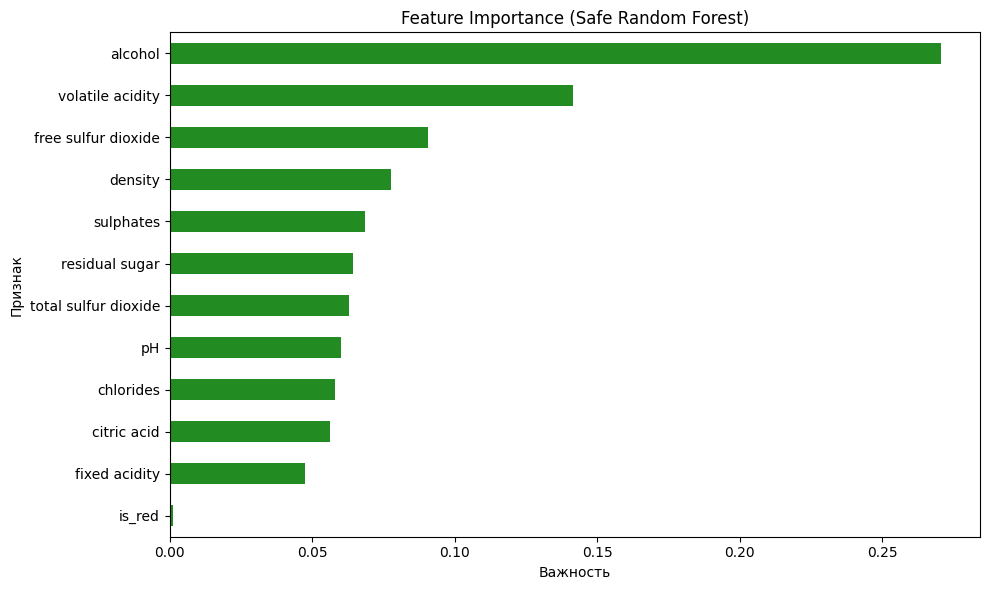

In [16]:
# Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Итоговый лес с лучшими безопасными параметрами от RandomizedSearchCV
rf_fixed = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,               # Максимальная глубина
    min_samples_split=5,        # Минимальное число объектов для разделения
    min_samples_leaf=4,         # В листе должно оставаться минимум 4 объекта
    max_features=0.8,           # Доля признаков для каждого дерева
    bootstrap=True,             # Включаем бэггинг
    random_state=42,
    n_jobs=-1
)

# Обучаем на трейне
rf_fixed.fit(XTrainAfterScaled, y_train)

# Проверяем RMSE на трейне
y_pred_train = rf_fixed.predict(XTrainAfterScaled)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"Новый RMSE на трейне: {train_rmse:.4f}")

# Проверяем кросс-валидацию
scores = cross_val_score(rf_fixed, XTrainAfterScaled, y_train, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
cv_rmse = np.sqrt(-scores)
print(f"Новый RMSE на кросс-валидации (среднее): {cv_rmse.mean():.4f}")

# Считаем важность признаков для обученной модели
importances = pd.Series(rf_fixed.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nВажность признаков (Feature Importance):")
print(importances)

# Графики важности признаков
plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='forestgreen')
plt.title('Feature Importance (Safe Random Forest)')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.gca().invert_yaxis() # Самый важный сверху
plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Делаем предсказания на тестовой выборке
y_pred_test = rf_fixed.predict(XTestAfterScaled)

#  Считаем RMSE на тесте
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"RMSE на тестовой выборке: {test_rmse:.4f}")

# Сравнение для выводов
print(f"Трейн RMSE: {train_rmse:.4f}")
print(f"Кросс-валидация RMSE: {cv_rmse.mean():.4f}")
print(f"Тест RMSE: {test_rmse:.4f}")

RMSE на тестовой выборке: 0.6199
Трейн RMSE: 0.4095
Кросс-валидация RMSE: 0.6402
Тест RMSE: 0.6199


Gradient Boosting - Test RMSE: 0.6763, MAE: 0.5343

Важность признаков (Feature Importance) в Gradient Boosting:
alcohol                 0.433310
volatile acidity        0.191024
free sulfur dioxide     0.093513
sulphates               0.057476
residual sugar          0.049067
total sulfur dioxide    0.036635
chlorides               0.036397
citric acid             0.031754
pH                      0.028139
density                 0.024642
fixed acidity           0.010585
is_red                  0.007458
dtype: float64


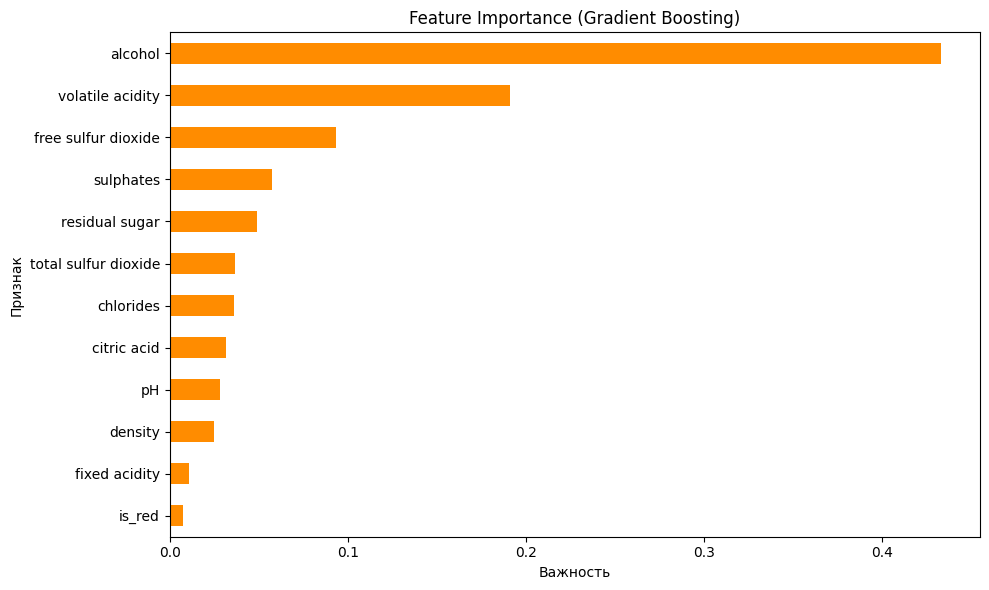

In [18]:
from sklearn.ensemble import GradientBoostingRegressor

# инициализация и обучение Градиентного бустинга
# БАЗОВАЯ МОДЕЛЬ ДЛЯ БУСТИНГА БЕЗ ПОДБОРА ПАРАМЕТРОВ
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(XTrainAfterScaled, y_train)

# предсказания и оценка на тесте
y_pred_gb = gb_model.predict(XTestAfterScaled)
gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))
gb_mae = mean_absolute_error(y_test, y_pred_gb)

print(f"Gradient Boosting - Test RMSE: {gb_rmse:.4f}, MAE: {gb_mae:.4f}")

# важность признаков для бустинга
gb_importances = pd.Series(
    gb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("\nВажность признаков (Feature Importance) в Gradient Boosting:")
print(gb_importances)

# визуализация важности
plt.figure(figsize=(10, 6))
gb_importances.plot(kind='barh', color='darkorange')
plt.title('Feature Importance (Gradient Boosting)')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Инициализируем базовую модель бустинга
gb_base = GradientBoostingRegressor(random_state=42)

# Задаем более безопасную и консервативную сетку параметров для предотвращения переобучения
param_dist_gb = {
    'n_estimators': [100, 150, 200, 250],        # Достаточное количество деревьев
    'learning_rate': [0.01, 0.03, 0.05, 0.1],      # Снижаем шаг обучения для плавной сходимости
    'max_depth': [3, 4],                          # Ограничиваем глубину дерева (стандарт для бустинга)
    'min_samples_split': [10, 20, 30],            # Требуем больше объектов для разделения узла
    'min_samples_leaf': [4, 8, 12],                # Исключаем слишком мелкие листья
    'subsample': [0.7, 0.8, 0.9]                  # Используем стохастический бустинг для регуляризации
}

# Настраиваем RandomizedSearchCV
random_search_gb = RandomizedSearchCV(
    estimator=gb_base,
    param_distributions=param_dist_gb,
    n_iter=30,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Запускаем поиск на тренировочных данных
random_search_gb.fit(XTrainAfterScaled, y_train)

# Достаем лучшую модель
gb_best = random_search_gb.best_estimator_
print("\nЛучшие БЕЗОПАСНЫЕ параметры для Gradient Boosting:")
print(random_search_gb.best_params_)

# Проверяем качество на тесте и трейне
y_pred_gb_best = gb_best.predict(XTestAfterScaled)
y_pred_gb_best_train = gb_best.predict(XTrainAfterScaled)

gb_best_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb_best))
gb_best_mae = mean_absolute_error(y_test, y_pred_gb_best)
gb_train_rmse_new = np.sqrt(mean_squared_error(y_train, y_pred_gb_best_train))

print(f"\nGradient Boosting (New Train RMSE): {gb_train_rmse_new:.4f}")
print(f"Gradient Boosting (New Test RMSE):  {gb_best_rmse:.4f}")
print(f"New MAE: {gb_best_mae:.4f}")
print(f"Новая разница (Test - Train): {gb_best_rmse - gb_train_rmse_new:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Лучшие БЕЗОПАСНЫЕ параметры для Gradient Boosting:
{'subsample': 0.8, 'n_estimators': 250, 'min_samples_split': 20, 'min_samples_leaf': 4, 'max_depth': 4, 'learning_rate': 0.1}

Gradient Boosting (New Train RMSE): 0.5057
Gradient Boosting (New Test RMSE):  0.6436
New MAE: 0.4987
Новая разница (Test - Train): 0.1380


In [20]:
# Проверяем RMSE на тренировочной выборке для сравнения с тестом
y_pred_gb_train = gb_best.predict(XTrainAfterScaled)
gb_train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_gb_train))

print("=== Проверка на переобучение (Gradient Boosting) ===")
print(f"RMSE на Train: {gb_train_rmse:.4f}")
print(f"RMSE на Test:  {gb_best_rmse:.4f}")
print(f"Разница (Test - Train): {gb_best_rmse - gb_train_rmse:.4f}")

# Если разница слишком велика (например, Train RMSE < 0.35, а Test 0.61),
# то модель переобучена, и стоит ограничить max_depth до 3-4 или уменьшить learning_rate.

=== Проверка на переобучение (Gradient Boosting) ===
RMSE на Train: 0.5057
RMSE на Test:  0.6436
Разница (Test - Train): 0.1380


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Собираем метрики из ранее рассчитанных переменных
results_data = {
    "Модель": [
        "Baseline (Медиана)",
        "Linear Regression",
        "Linear Regression (Filtered Features)",
        "Ridge (L2 Regression)",
        "Lasso (L1 Regression)",
        "Random Forest (Safe tuned)",
        "Gradient Boosting (Safe tuned)"
    ],
    "Train RMSE": [
        np.nan, # у бейслайна нет обучения
        np.sqrt(mean_squared_error(y_train, lr_model.predict(XTrainAfterScaled))),
        np.sqrt(mean_squared_error(y_train, lr_f.predict(X_tr_f_scaled))),
        np.sqrt(mean_squared_error(y_train, ridge.predict(X_train_scaled))),
        np.sqrt(mean_squared_error(y_train, lasso.predict(X_train_scaled))),
        np.sqrt(mean_squared_error(y_train, rf_fixed.predict(XTrainAfterScaled))),
        gb_train_rmse_new
    ],
    "Test RMSE": [
        RMSE, # Baseline RMSE
        lr_model_rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_lr_f)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
        test_rmse, # RF Test RMSE
        gb_best_rmse
    ],
    "Test MAE": [
        MAE,
        lr_model_mae,
        mean_absolute_error(y_test, y_pred_lr_f),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso),
        mean_absolute_error(y_test, y_pred_test), # Считаем напрямую из предсказаний RF
        gb_best_mae
    ]
}

# Создаем датафрейм
df_results = pd.DataFrame(results_data)

# Рассчитываем разницу для контроля переобучения (где применимо)
df_results["Разница RMSE (Test - Train)"] = df_results["Test RMSE"] - df_results["Train RMSE"]

# Сортируем модели по качеству на тестовой выборке (чем меньше RMSE, тем лучше)
df_results = df_results.sort_values(by="Test RMSE").reset_index(drop=True)

display(df_results.style.highlight_min(subset=["Test RMSE", "Test MAE"], color='lightgreen'))

=== СРАВНИТЕЛЬНАЯ ТАБЛИЦА ВСЕХ МОДЕЛЕЙ ===


,Модель,Train RMSE,Test RMSE,Test MAE,Разница RMSE (Test - Train)
0,Random Forest (Safe tuned),0.409488,0.619922,0.468977,0.210435
1,Gradient Boosting (Safe tuned),0.505678,0.643641,0.498666,0.137962
2,Linear Regression,0.736694,0.716511,0.561961,-0.020184
3,Ridge (L2 Regression),0.736704,0.716756,0.562100,-0.019948
4,Lasso (L1 Regression),0.740418,0.725590,0.568380,-0.014828
5,Linear Regression (Filtered Features),0.747424,0.735637,0.576563,-0.011787
6,Baseline (Медиана),nan,0.901281,0.650769,nan
